# Lead-time metrics from holdout predictions

One score per forecast step (+1 to +6). Predictions and last-frame persistence are always evaluated on the **same observed vegetation pixels**. Values come from the saved, reconstructed prediction tensors. 

## 1. Imports and run paths

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import yaml

In [2]:
PROJECT = Path.home() / "OneDrive" / "Documents" / "Master Thesis"
REPO = PROJECT / "ARCEME-Vegetation-Recovery"
RUN = REPO / "model/wand_db_logs/FinalRefit_SGEDConvLSTM_RGBI_kNDVI_2026-10-07_19-31-23"
SOURCE = PROJECT / "data/final_analysis/test_essential"
OUTPUT = REPO / "evaluation/paper_figures/final_plots/lead_time_analysis/live_metrics"

with (RUN / "config_used.yaml").open(encoding="utf-8") as f:
    config = yaml.safe_load(f)
rules = config["training"]["validation"]
MIN_COUNT = int(rules["min_valid_target_count"])
MIN_COVERAGE = float(rules["min_valid_target_coverage"])
MIN_VARIANCE = float(rules["min_target_variance"])
STEPS = range(1, int(config["data"]["target_length"]) + 1)
EPS = 1e-8  # used for the training logger's micro NSE and persistence skill

manifest = (RUN / "holdout_cubes_26.txt").read_text(encoding="utf-8").splitlines()
cube_ids = [Path(s.strip()).name.removesuffix("_postprocessed.zarr") for s in manifest if s.strip()]
if not cube_ids or len(cube_ids) != len(set(cube_ids)):
    raise ValueError("Empty manifest or duplicate cube IDs.")
if config["model"]["baseline"] != "last_frame":
    raise ValueError("Expected an exported last-frame persistence baseline.")

# This is the only CSV input: reconstruction status is not stored in the tensors.
complete = pd.read_csv(RUN / "metrics/cube_metrics.csv", usecols=["id", "reconstruction_complete"])
status = complete.set_index("id", verify_integrity=True)["reconstruction_complete"].reindex(cube_ids)
bad = status.index[~status.astype(str).str.lower().eq("true")].tolist()
if bad:
    raise ValueError(f"Missing audit or incomplete reconstruction: {bad}")

print(f"{len(cube_ids)} cubes | +1 to +{STEPS.stop-1} | count ≥ {MIN_COUNT}, "
      f"coverage ≥ {MIN_COVERAGE:.0%}, target variance ≥ {MIN_VARIANCE:g}")

26 cubes | +1 to +6 | count ≥ 1000, coverage ≥ 15%, target variance ≥ 1e-06


## 2. Read each cube once

The export supplies target, prediction, persistence and observation mask on the same grid. The source cube supplies the static vegetation mask, including vegetated pixels hidden by clouds. Coverage at a given step is the number of valid vegetated pixels divided by the number of vegetated pixels in that cube. 

In [4]:
def read_cube(cid):
    source = SOURCE / f"{cid}_postprocessed.zarr"
    with xr.open_zarr(source, chunks=None, mask_and_scale=False) as ds:
        veg = ds["is_veg"]
        if "time_sentinel_2_l2a" in veg.dims:
            veg = veg.isel(time_sentinel_2_l2a=0)
        veg = veg.transpose("y", "x").values > 0.5
    n_veg = int(veg.sum())

    with xr.open_zarr(RUN / "tensors" / f"{cid}.zarr", chunks=None, mask_and_scale=False) as ds:
        true, pred, base, mask = [
            ds[v].transpose("time", "y", "x").values for v in ("true", "pred", "base", "mask")
        ]
    if true.shape != (len(STEPS), *veg.shape):
        raise ValueError(f"{cid}: tensor grid or forecast length mismatch")

    for t, step in enumerate(STEPS):
        observed = mask[t] > 0.5
        if (observed & ~veg).any():
            raise ValueError(f"{cid}, +{step}: exported evaluation mask extends beyond vegetation")
        ok = observed & veg
        y = true[t][ok].astype("float64")
        n = y.size
        if not np.isfinite(y).all():
            raise ValueError(f"{cid}, +{step}: non-finite target on the evaluation mask")
        y_mean = y.mean() if n else np.nan
        sst = np.square(y - y_mean).sum() if n else 0.0
        coverage = n / n_veg if n_veg else 0.0

        # Separate float32 reductions for the training logger's pooled step metrics.
        y32 = true[t][ok].astype("float32", copy=False)
        y_sum32, y_sq32 = y32.sum(), np.square(y32).sum()
        for name, values in (("Predicted", pred[t]), ("Persistence", base[t])):
            err = values[ok].astype("float64") - y
            if not np.isfinite(err).all():
                raise ValueError(f"{cid}, +{step}: non-finite {name} on the evaluation mask")
            sq = np.square(err)
            err32 = err.astype("float32")
            yield dict(cube_id=cid, step=step, curve=name, n=n, n_veg=n_veg,
                       coverage=coverage, y_mean=y_mean, sst=sst,
                       var_y=sst / n if n else np.nan, err=err.sum(),
                       abs_err=np.abs(err).sum(), sse=sq.sum(), fourth=np.square(sq).sum(),
                       y_sum32=y_sum32, y_sq32=y_sq32, sse32=np.square(err32).sum(),
                       err32=err32.sum(), abs_err32=np.abs(err32).sum())

In [5]:
stats = pd.DataFrame(row for cid in cube_ids for row in read_cube(cid))
# For persistence skill the comparator is the saved baseline on exactly the same pixels
idx = ["cube_id", "step"]
baseline = stats.loc[stats.curve.eq("Persistence")].set_index(idx)[["sse", "sse32"]]
stats = stats.join(baseline.add_prefix("base_"), on=idx, validate="many_to_one")
print(f"Loaded {stats.cube_id.nunique()} cubes. Plot cells below reuse these statistics.")

Loaded 26 cubes. Plot cells below reuse these statistics.


In [ ]:
rows = []

# Die Predicted-Zeilen enthalten sowohl sse (Modell) als auch base_sse (Persistence).
for cid, g in stats.loc[stats["curve"].eq("Predicted")].groupby("cube_id"):
    n_possible = len(STEPS) * g["n_veg"].iloc[0]
    g = g.loc[g["n"] > 0]
    n = g["n"].sum()

    # Eligibility einmal für den gesamten Cube prüfen, nicht pro Schritt.
    if n < MIN_COUNT or n_possible == 0 or n / n_possible < MIN_COVERAGE:
        continue

    mean_y = np.average(g["y_mean"], weights=g["n"])
    sst = (g["sst"] + g["n"] * (g["y_mean"] - mean_y)**2).sum()
    if sst <= 0 or sst / n < MIN_VARIANCE:
        continue

    # NNSE = 1 / (2 - NSE) = 1 / (1 + SSE / SST)
    rows.append({
        "cube_id": cid,
        "NNSE":      1 / (1 + g["sse"].sum() / sst),
        "NNSE_base": 1 / (1 + g["base_sse"].sum() / sst),
    })

overall = pd.DataFrame(rows).set_index("cube_id")
display(overall.round(6))                  # values for each eligible cube
print(f"Eligible cubes: {len(overall)}")
print(overall.mean().round(6))             # Macro-NNSE average across all cubes

,NNSE,NNSE_base
cube_id,,
2016-0272-MLI,0.457000,0.160293
2017-0091-ZWE,0.816168,0.632372
2017-0168-MEX,0.125656,0.061034
2017-0186-NER,0.600963,0.541853
2018-0103-BWA,0.475854,0.668429
2018-0376-PRT,0.782029,0.731237
2019-0413-ESP,0.324204,0.521521
2019-0519-MEX,0.538146,0.380254
2020-0218-HND,0.794621,0.569815


Eligible cubes: 21
NNSE         0.585344
NNSE_base    0.522103
dtype: float64


## 3. Scores, weighting and dispersion

- **Cube:** score each cube at that step, then average scores with equal weights. NSE (called R² in training) uses the spatial target mean for that **cube and step**: `1 − SSE/SST`. NNSE is `1/(2 − NSE)` **before** averaging. Bands/bars show the sample SD of the contributing cube scores (at least two cubes).
- **Pixel:** pool valid pixels first, then score the pool. Micro NSE uses one target mean for the **whole step**, not the mean of cube NSEs. As in the step logger, sums are accumulated in float32 and the denominator is `SST + 1e−8`. RMSE is derived from MSE. Skill is `1 − MSE / (MSE_persistence + 1e−8)` and is reported for the model.
- **Single cube:** no averaging over cubes. For single-cube or pixel plots, SD is available for MAE, Bias and MSE: dispersion of absolute, signed or squared pixel errors, respectively. RMSE, NSE, NNSE and skill are single scores for the pool
- **Eligibility:** `"slice"` reproduces the lead-time figure: count and coverage per cube-step for all metrics, plus target variance for NSE/NNSE. `"off"` uses all observed locations. `"variance_only"` applies all three gates only to cube-step NSE/NNSE, analogous to the training **whole-cube** policy. 

In [8]:
METRICS = ("MAE", "MSE", "RMSE", "Bias", "NSE", "NNSE", "Skill")
EFFICIENCIES = {"NSE", "NNSE"}
PIXEL_SD = {"MAE", "MSE", "Bias"}


def score(z, metric, micro=False):
    mse = z["sse"] / z["n"]
    if metric == "MAE":
        return z["abs_err"] / z["n"]
    if metric == "MSE":
        return mse
    if metric == "RMSE":
        return np.sqrt(mse)
    if metric == "Bias":
        return z["err"] / z["n"]
    if metric == "Skill":
        return 1 - mse / (z["base_sse"] / z["n"] + EPS)
    nse = 1 - z["sse"] / (z["sst"] + (EPS if micro else 0))
    return nse if metric == "NSE" else 1 / (2 - nse)


def pool_for_logger(g):
    # Original step logger: sum per-cube totals sequentially in float32.
    def add(column):
        return float(np.cumsum(g[column].to_numpy(dtype="float32"), dtype="float32")[-1])

    n = add("n")
    return dict(n=n, err=add("err32"), abs_err=add("abs_err32"),
                sse=add("sse32"), base_sse=add("base_sse32"),
                sst=add("y_sq32") - add("y_sum32")**2 / n)


def pixel_sd(g, metric):
    n = int(g.n.sum())
    if metric not in PIXEL_SD or n < 2:
        return np.nan
    total, second = {"Bias": ("err", "sse"), "MAE": ("abs_err", "sse"),
                     "MSE": ("sse", "fourth")}[metric]
    variance = g[second].sum() / n - (g[total].sum() / n)**2
    return np.sqrt(max(0.0, variance))

In [56]:
def summarize(data, *, mode, eligibility, metrics, ids=None):
    if isinstance(metrics, str):
        metrics = (metrics,)
    if not metrics or not set(metrics).issubset(METRICS):
        raise ValueError(f"Choose metrics from {METRICS}")
    if mode not in {"cube", "pixel", "single"} or eligibility not in {"off", "slice", "variance_only"}:
        raise ValueError("Unknown aggregation mode or eligibility policy.")
    ids = list(data.cube_id.unique()) if ids is None else ([ids] if isinstance(ids, str) else list(ids))
    if not ids or len(set(ids)) != len(ids) or set(ids) - set(data.cube_id):
        raise ValueError("Empty selection, duplicate or unknown cube ID.")
    if mode == "single" and len(ids) != 1:
        raise ValueError("Single-cube mode requires exactly one cube ID.")
    if mode == "pixel" and eligibility == "variance_only":
        raise ValueError("Use 'off' for training micro or 'slice' for a filtered pixel pool.")

    subset = data.loc[data.cube_id.isin(ids) & data.n.gt(0)]
    enough = subset.n.ge(MIN_COUNT) & subset.coverage.ge(MIN_COVERAGE)
    out = []
    single_flags = {}
    for metric in metrics:
        efficiency = metric in EFFICIENCIES
        gated = eligibility == "slice" or (eligibility == "variance_only" and efficiency)
        # Same per-metric gate for the filtered cube mean and single-cube markers.
        slice_ok = enough & subset.var_y.ge(MIN_VARIANCE) & subset.sst.gt(0) if efficiency else enough
        take = slice_ok if gated else pd.Series(True, index=subset.index)
        if not gated and efficiency and mode != "pixel":
            take &= subset.sst.gt(0)
        curves = ("Predicted",) if metric == "Skill" else ("Predicted", "Persistence")
        for (step, curve), g in subset.loc[take & subset.curve.isin(curves)].groupby(["step", "curve"]):
            if mode == "pixel":
                value, sd = score(pool_for_logger(g), metric, micro=True), pixel_sd(g, metric)
            else:
                values = score(g, metric)
                value = values.mean()
                sd = values.std(ddof=1) if mode == "cube" else pixel_sd(g, metric)
            if mode == "single":
                single_flags[(step, curve, metric)] = bool(slice_ok.loc[g.index[0]])
            out.append(dict(step=step, curve=curve, metric=metric, value=value, sd=sd,
                            n_cubes=g.cube_id.nunique(), n_pixels=int(g.n.sum())))
    # Explicit missing steps: no observations is a gap, never a score of zero.
    columns = ["step", "curve", "metric", "value", "sd", "n_cubes", "n_pixels"]
    index = pd.MultiIndex.from_tuples(
        [(s, c, m) for m in metrics for c in ("Predicted", "Persistence")
         if m != "Skill" or c == "Predicted" for s in STEPS], names=columns[:3])
    table = pd.DataFrame(out, columns=columns).set_index(columns[:3]).reindex(index)
    counts = ["n_cubes", "n_pixels"]
    table[counts] = table[counts].astype(float).fillna(0).astype(int)
    table[["value", "sd"]] = table[["value", "sd"]].astype(float)
    if mode == "single":
        table["in_filtered_mean"] = [single_flags.get(key, False) for key in table.index]
    return table.reset_index()

## 4. Plot function

Orange dashed squares are model predictions; symmetric bars show ±1 SD. Grey dotted triangles are persistence; the grey band shows ±1 SD. Section 5 controls which curves and metrics show SD. Horizontal reference lines mark the target-mean benchmark (NSE = 0, NNSE = 0.5), zero MAE (perfect prediction), zero Bias (no net bias) and zero Skill (no improvement over persistence). Counts refer to each metric. 

In [60]:
STYLES = {"Predicted": ("#D55E00", "s--"), "Persistence": ("#707070", "^:")}
REFERENCES = {"NNSE": (0.5, "Target mean"), "NSE": (0, "Target mean"),
              "MAE": (0, "Perfect prediction"), "Bias": (0, "No net bias"),
              "Skill": (0, "No gain over persistence")}


def plot_metrics(table, *, mode, eligibility, title="", spread=None,
                 sd_for=("Predicted", "Persistence"), sd_metrics=None,
                 show_persistence=True, show_references=True, filename=None):
    if spread not in {None, "by_curve", "bars", "band"}:
        raise ValueError("spread must be None, 'by_curve', 'bars' or 'band'")
    metrics = table.metric.unique()
    cols = min(2, len(metrics))
    rows = (len(metrics) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, squeeze=False, figsize=(5.2*cols, 3.4*rows),
                             layout="constrained")
    for letter, ax, metric in zip("abcdefghijklmnopqrstuvwxyz", axes.flat, metrics):
        ax.set_title(f"{letter}) {metric}", loc="left")
        block = table.loc[table.metric.eq(metric)]
        has_open = False
        for curve, (color, style) in STYLES.items():
            g = block.loc[block.curve.eq(curve)].set_index("step").reindex(STEPS)
            if curve == "Persistence" and (not show_persistence or metric == "Skill"):
                continue
            x = g.index.to_numpy()
            y, sd = g["value"].to_numpy(), g["sd"].to_numpy()
            kind = ("bars" if curve == "Predicted" else "band") if spread == "by_curve" else spread
            draw = (kind is not None and curve in sd_for
                    and (sd_metrics is None or metric in sd_metrics) and np.isfinite(sd).any())
            unit = "cube" if mode == "cube" else "pixel error"
            label = curve + (f" (±1 {unit} SD)" if draw else "")
            line, = ax.plot(x, y, style, color=color, lw=1.7, ms=4, label=label, zorder=3)
            if mode == "single":
                included = g["in_filtered_mean"].eq(True).to_numpy(dtype=bool)
                omitted = np.isfinite(y) & ~included
                if omitted.any():
                    line.set_markevery(np.flatnonzero(included).tolist())
                    ax.plot(x[omitted], y[omitted], ls="none", marker=line.get_marker(),
                            ms=4, markerfacecolor="none", markeredgecolor=color, zorder=4)
                    has_open = True
            if draw and kind == "band":
                ax.fill_between(x, y-sd, y+sd, color=color, alpha=.16, linewidth=0, zorder=1)
            elif draw:
                ax.errorbar(x, y, yerr=sd, fmt="none", ecolor=color, lw=.9, capsize=3)
        if show_references and metric in REFERENCES:
            level, meaning = REFERENCES[metric]
            ax.axhline(level, ls="--", color="#000000", lw=.9, zorder=1.8,
                       label=f"{meaning} ({level:g})")
        g = block.loc[block.curve.eq("Predicted")].set_index("step").reindex(STEPS)
        if mode == "single":
            counts, what = [f"{n:,}" for n in g.n_pixels], "valid vegetation pixels"
            fig.suptitle(f"{title}")
        elif mode == "pixel":
            counts = [f"{n/1e6:.2f}" for  n in g.n_pixels]
            what = "valid pixels in millions"
        else:
            counts, what = g.n_cubes.astype(str), "contributing cubes"
        ax.set_xticks(STEPS, [f"+{s}\n({c})" for s, c in zip(STEPS, counts)])
        ax.set(xlabel=f"Forecast step \n({what})", ylabel=metric)
        ax.set_axisbelow(True)
        ax.grid(axis="y", color="0.90", lw=.8)
        ax.spines[["top", "right"]].set_visible(False)
        if has_open:
            ax.plot([], [], ls="none", marker="o", ms=4, mfc="none", mec="0.35",)
               #     label="Excluded from filtered cube mean")
        ax.legend(frameon=False, fontsize=8)
    for ax in list(axes.flat)[len(metrics):]:
        ax.set_visible(False)
    # fig.suptitle(f"{title} · {mode} · eligibility: {eligibility}".strip(" ·"))
    if filename:
        OUTPUT.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUTPUT / filename, dpi=300, bbox_inches="tight")
    plt.show()
    return fig

## 5. Choose metrics and cubes

Use `CUBE_IDS` for a named subset, or `N_CUBES` to draw a reproducible subset **once for all forecast steps and curves**. Leave both as `None` for the entire manifest. Individual missing or ineligible cube-steps can still drop out. Re-run from here when changing the selection.

In [39]:
PLOT_METRICS = ("NNSE", "NSE", "MAE", "Bias")  # also "MSE", "RMSE", "Skill"
SHOW_SD = False
SD_CURVES = {"Predicted"} #, "Persistence"}  # remove either curve to hide its SD
SD_METRICS = None                         # all available; e.g. {"NNSE", "MAE"}
SHOW_REFERENCES = True

plot_options = dict(spread="by_curve" if SHOW_SD else None, sd_for=SD_CURVES,
                    sd_metrics=SD_METRICS, show_references=SHOW_REFERENCES)
CUBE_IDS = None      # e.g. ["2021-0359-MEX", "2022-0445-SDN"]
N_CUBES = None       # e.g. 8; used only when CUBE_IDS is None
SEED = 777

if N_CUBES is not None and CUBE_IDS is not None:
    raise ValueError("Choose either N_CUBES or CUBE_IDS.")
if N_CUBES is None:
    selected = cube_ids if CUBE_IDS is None else CUBE_IDS
else:
    if not 1 <= N_CUBES <= len(cube_ids):
        raise ValueError(f"N_CUBES must be in 1..{len(cube_ids)}")
    selected = sorted(np.random.default_rng(SEED).choice(cube_ids, N_CUBES, replace=False))
print(f"Selected cubes ({len(selected)}):", ", ".join(selected))

Selected cubes (26): 2016-0272-MLI, 2016-0554-PAK, 2017-0091-ZWE, 2017-0168-MEX, 2017-0186-NER, 2017-0294-IND, 2018-0103-BWA, 2018-0267-IND, 2018-0376-PRT, 2019-0413-ESP, 2019-0519-MEX, 2019-0533-FRA, 2020-0218-HND, 2021-0270-YEM, 2021-0295-BGD, 2021-0325-MEX, 2021-0359-MEX, 2021-0392-CHL, 2021-0429-PAK, 2021-0442-USA, 2022-0442-AFG, 2022-0445-SDN, 2022-0609-ITA, 2023-0263-VNM, 2023-0570-TJK, 2023-0582-GRC


### 5a. Cube-weighted comparison, with and without eligibility

Both figures use the same cube selection and SD settings from section 5. Select one policy instead of both for a single figure.

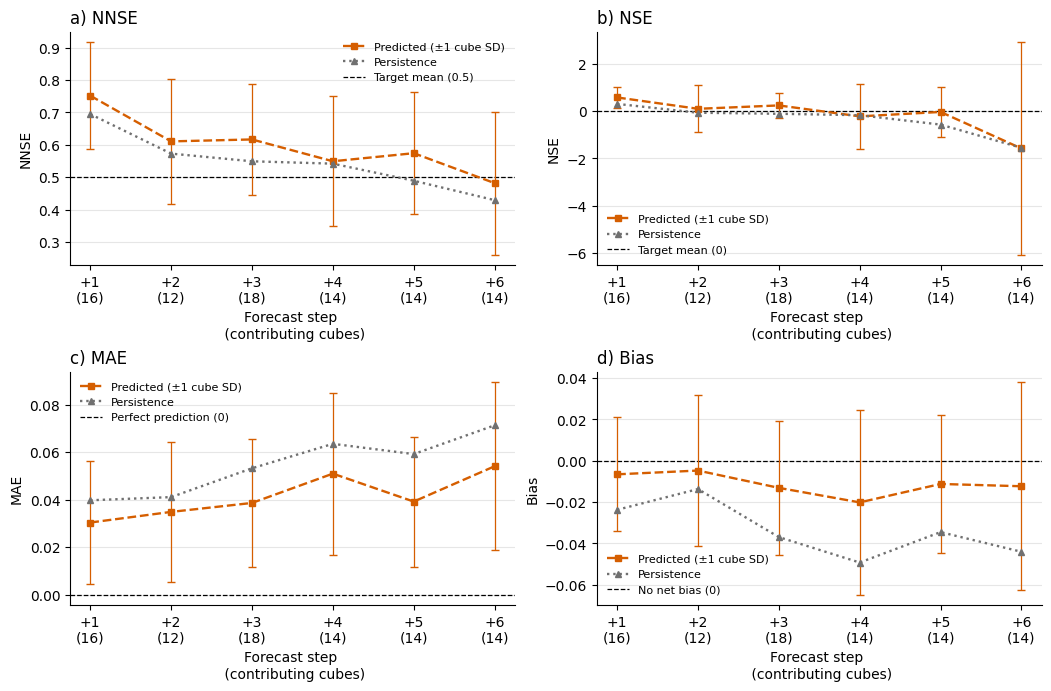

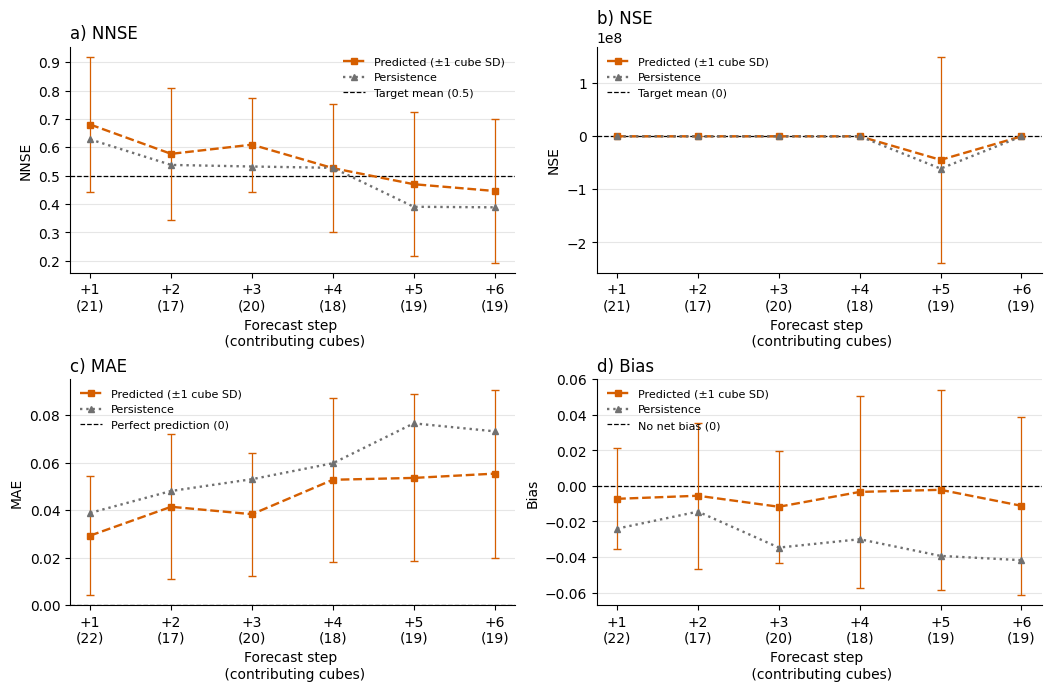

In [33]:
for policy in ("slice", "off"):
    if policy == "slice":
        n = 21
    else:
        n = len(selected)
    filename = f"lead_time_metrics_{n}cubes_SD_{SHOW_SD}.png"
    cube_scores = summarize(stats, mode="cube", eligibility=policy, metrics=PLOT_METRICS, ids=selected)
    plot_metrics(cube_scores, mode="cube", eligibility=policy, filename=filename,
                # title="Holdout · equal cube weights", 
                 **plot_options)

### 5b. Pixel-weighted metrics

Default: all valid observed vegetation pixels in the selected cubes. Change `policy` to `"slice"` to pool only qualifying cube-steps. Pixel numbers below the curves are in millions; the table retains exact counts.

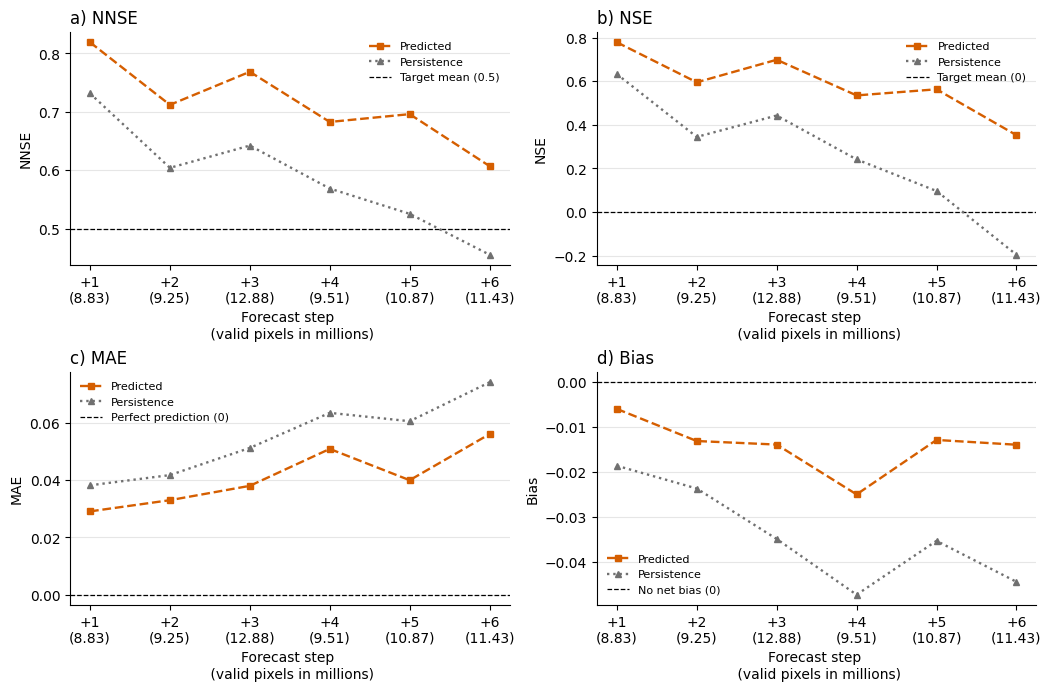

In [40]:
policy = "off"
filename = f"lead_time_metrics_pixel_weighted_SD_{SHOW_SD}.png"
micro_scores = summarize(stats, mode="pixel", eligibility=policy, metrics=PLOT_METRICS, ids=selected)
plot_metrics(micro_scores, mode="pixel", eligibility=policy, 
             filename=filename,
             #title="Holdout · pooled pixels",
             **plot_options);

### 5c. Individual cube

With eligibility `"off"`, filled markers meet the filtered cube-mean criteria for that metric, open markers fall outside them, and undefined scores remain gaps. With `"slice"`, excluded points are hidden. Choose any ID from the holdout manifest. Use `filename="my_plot.png"` inside a plot call to save it.

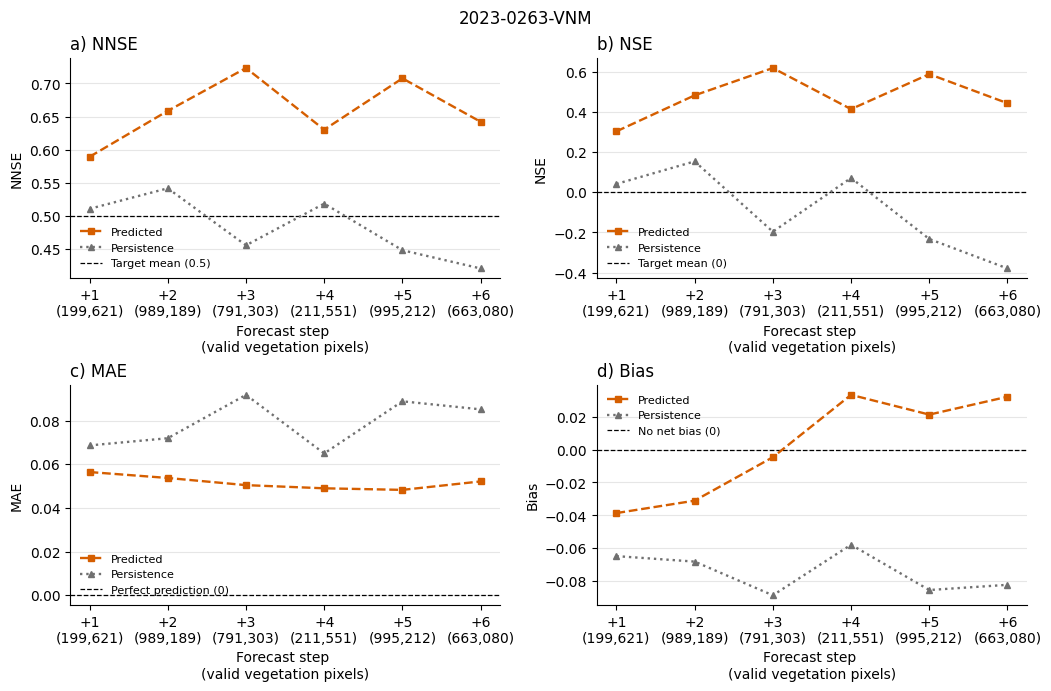

In [58]:
CUBE = "2023-0263-VNM"  # choose one cube for the single-cube plot
policy = "off"
single_scores = summarize(stats, mode="single", eligibility=policy, metrics=PLOT_METRICS, ids=[CUBE])
plot_metrics(single_scores, mode="single", eligibility=policy, title=CUBE, **plot_options);

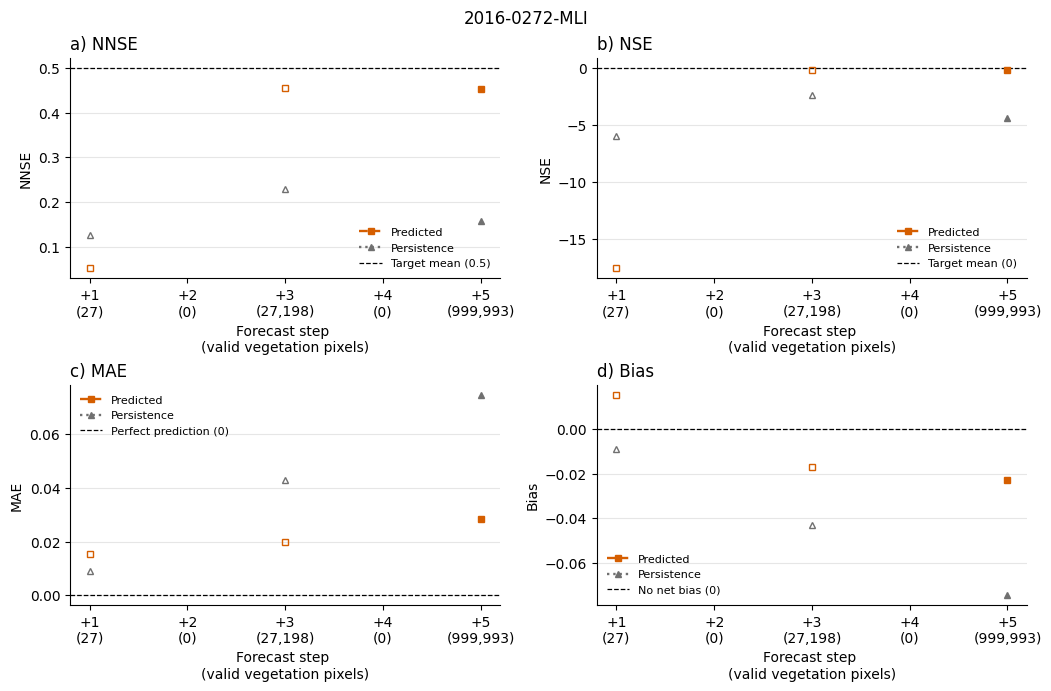

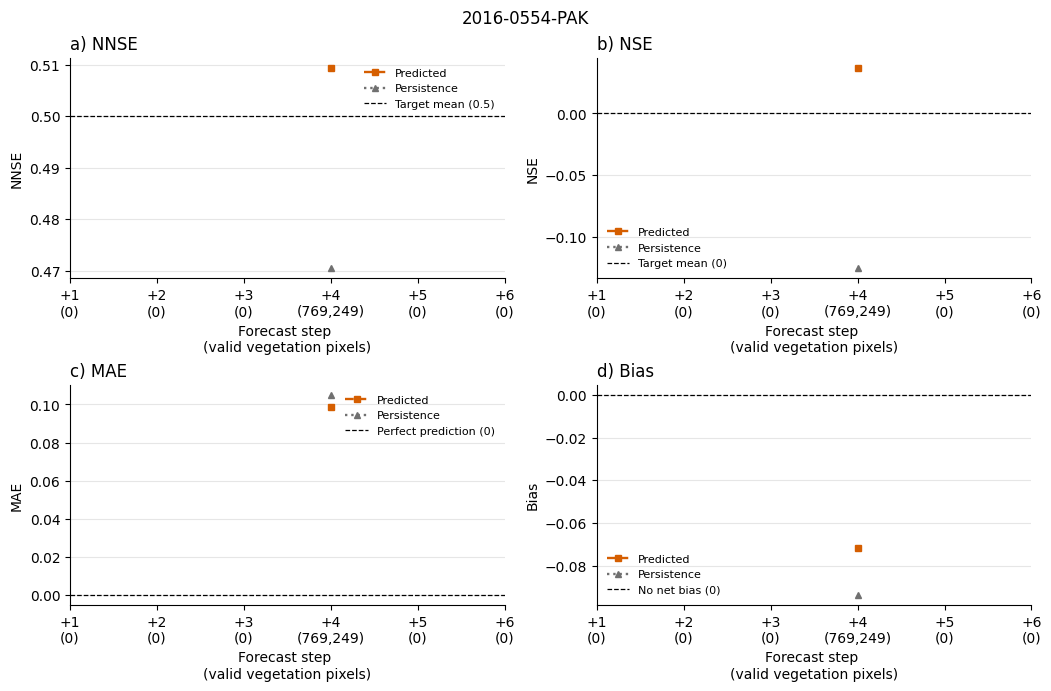

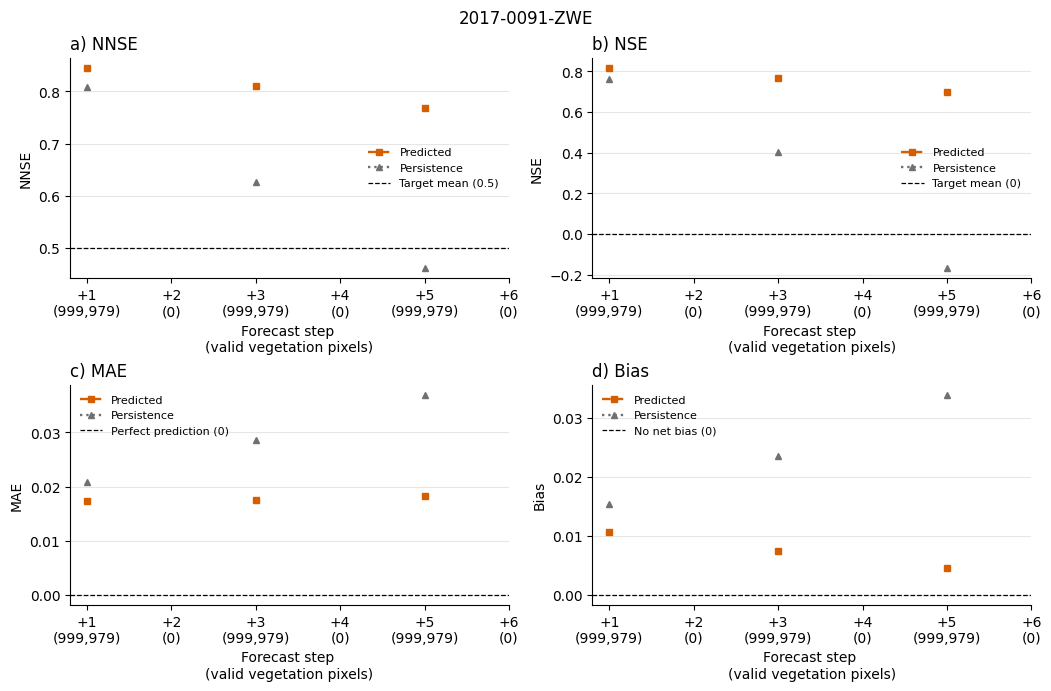

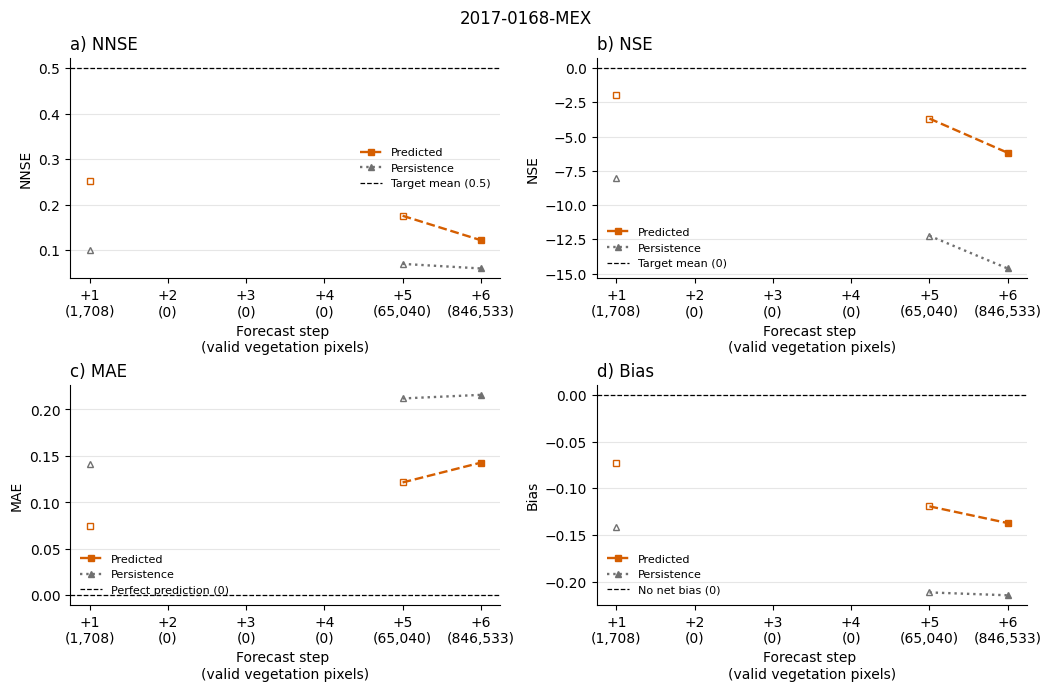

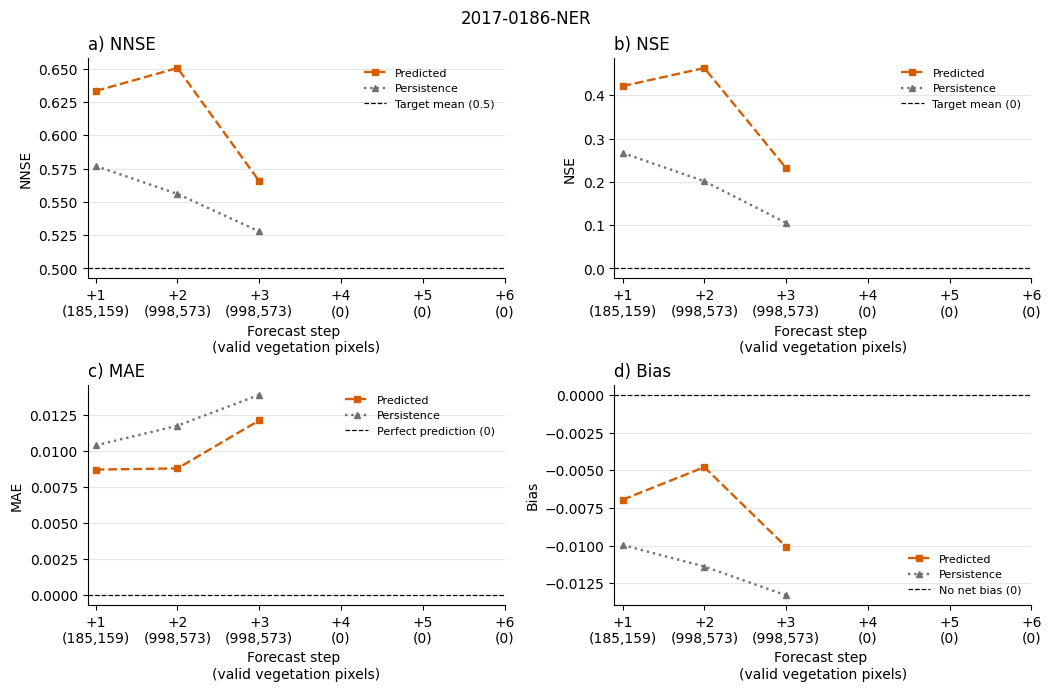

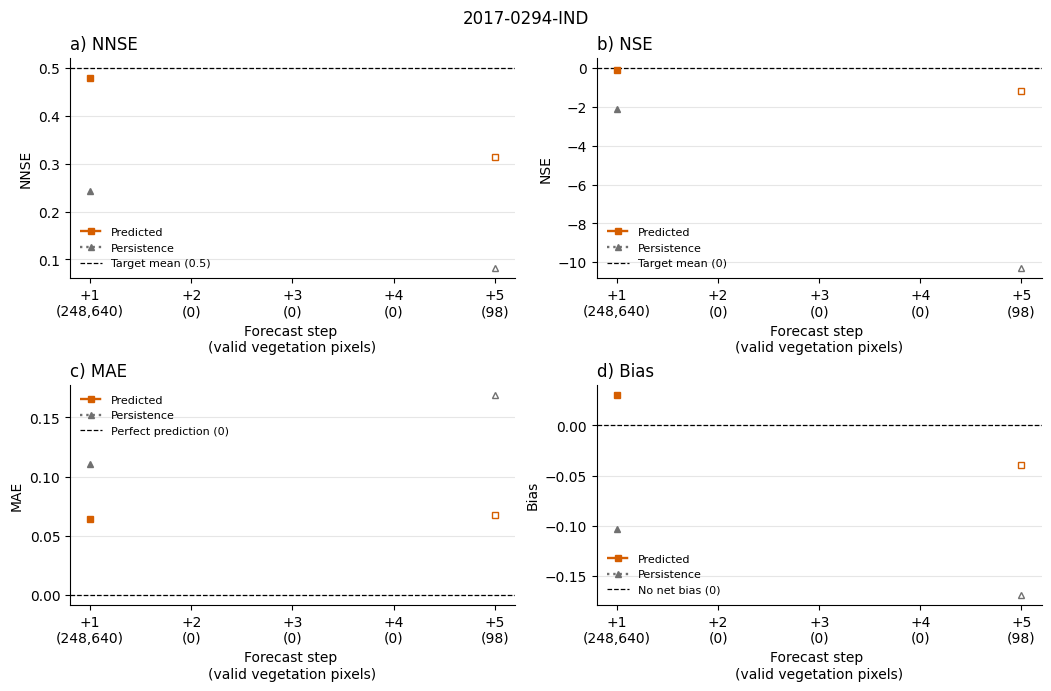

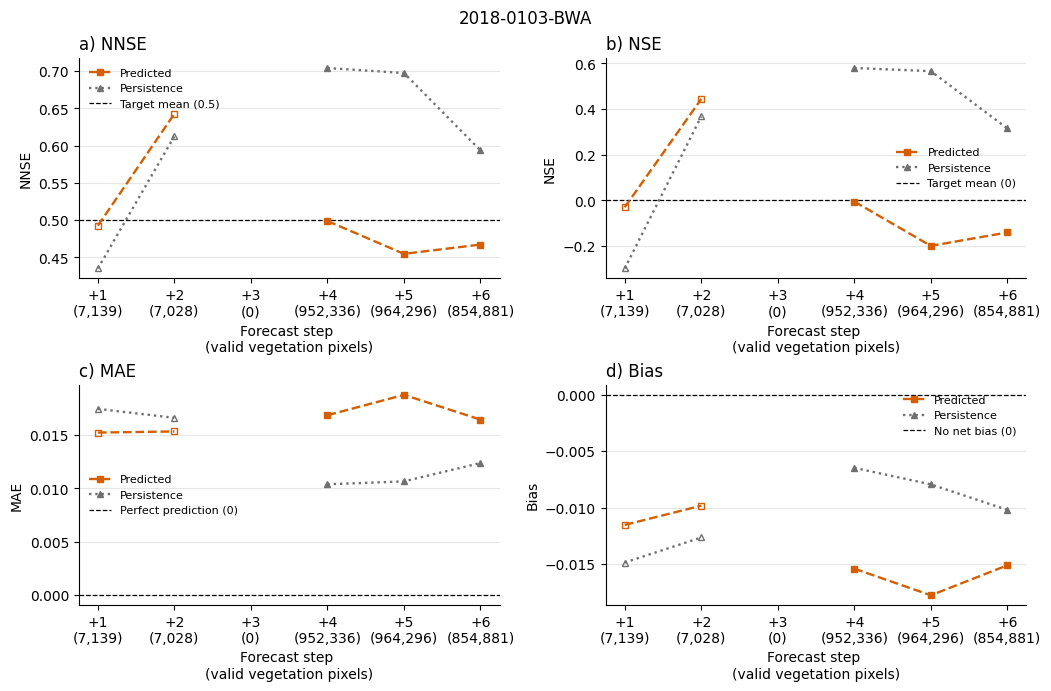

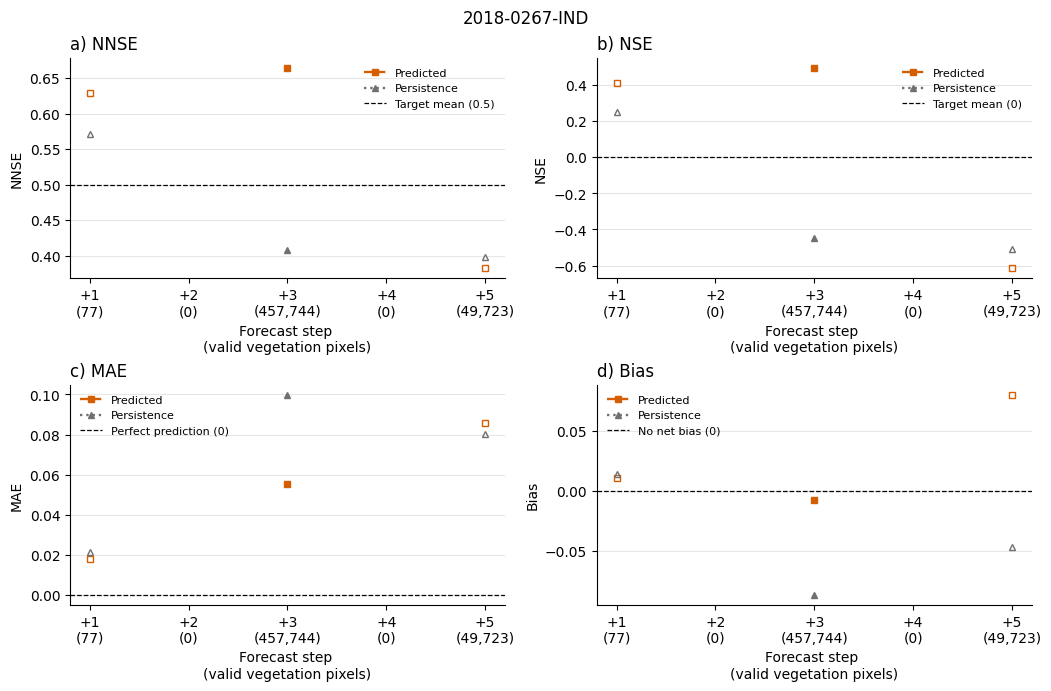

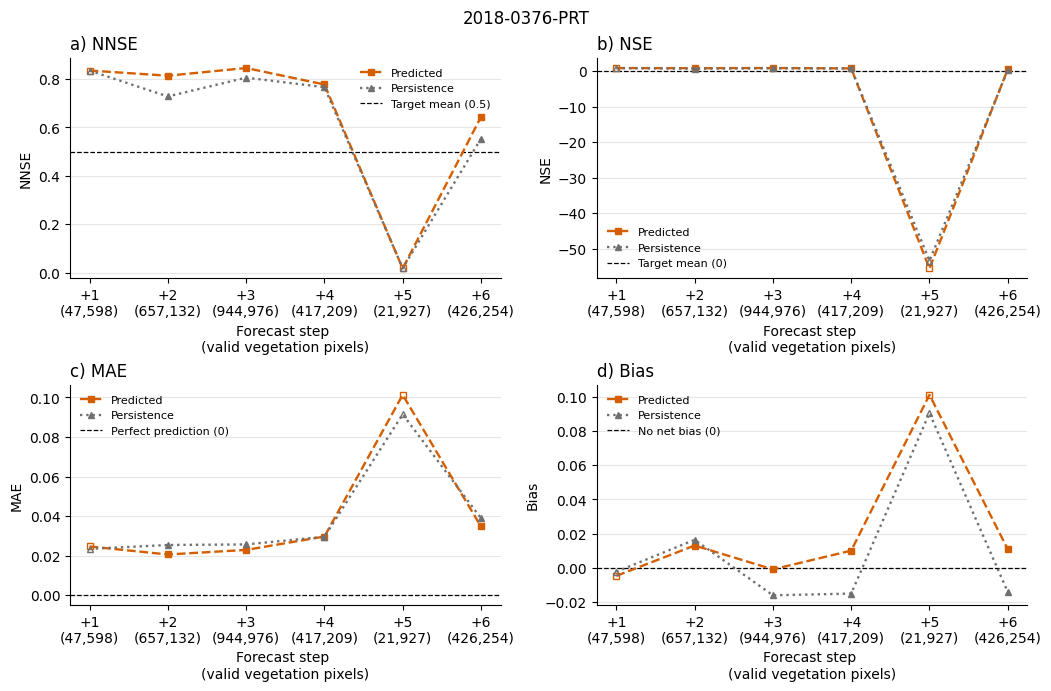

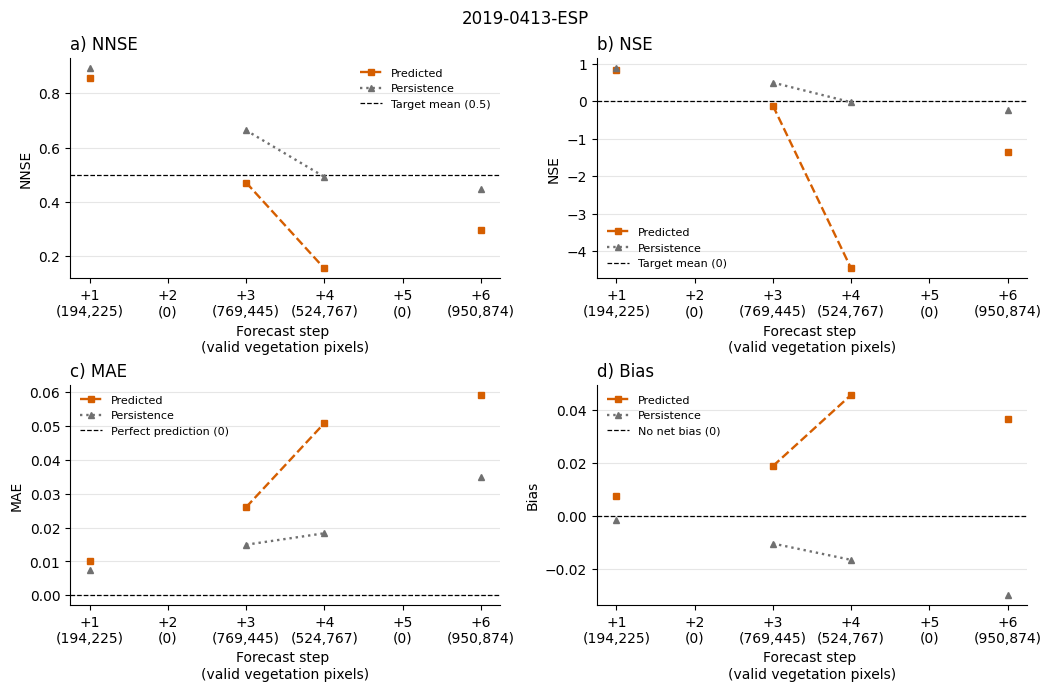

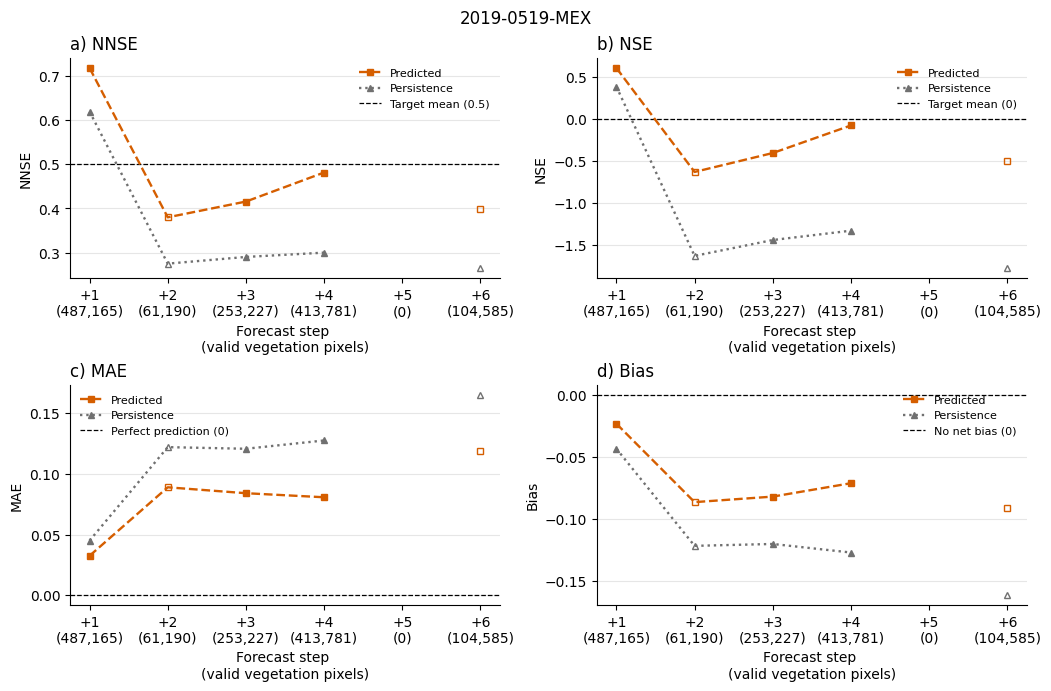

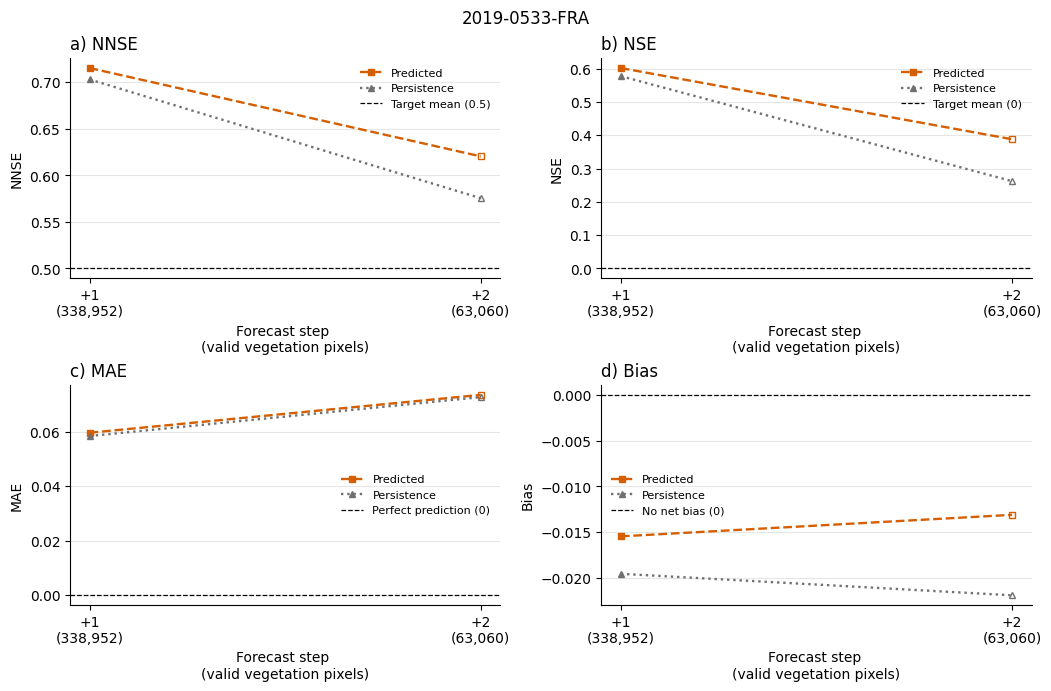

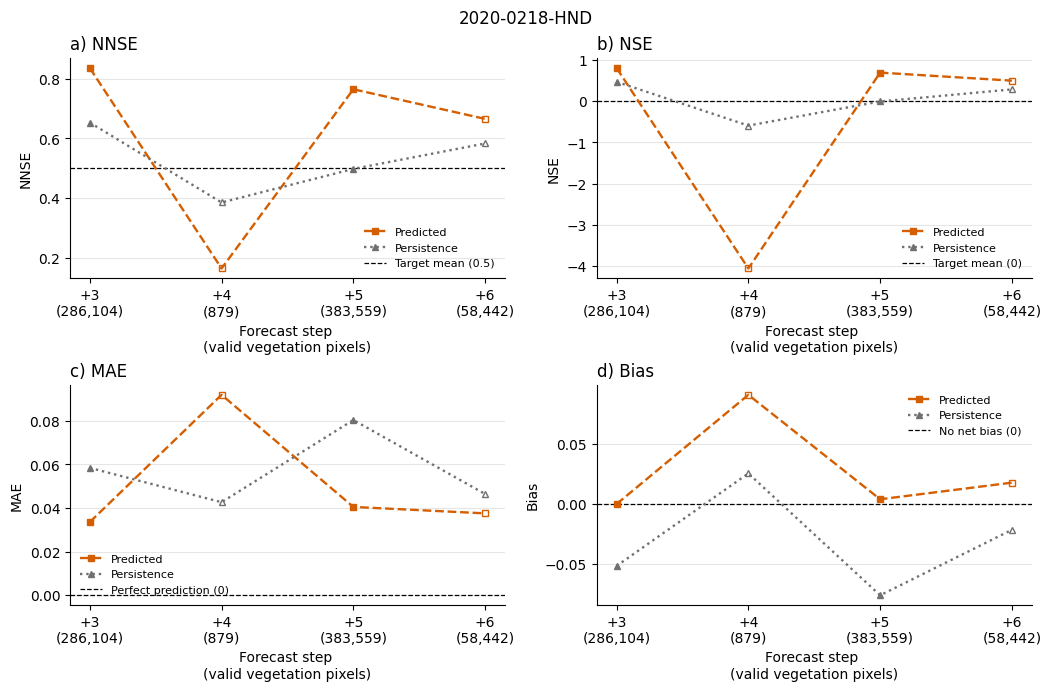

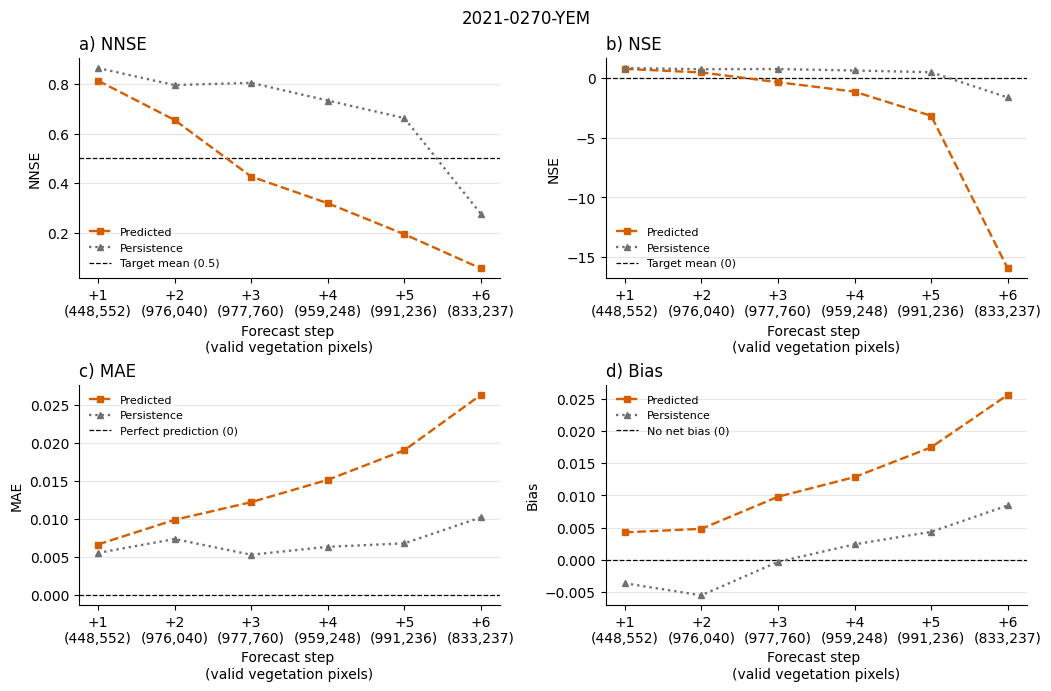

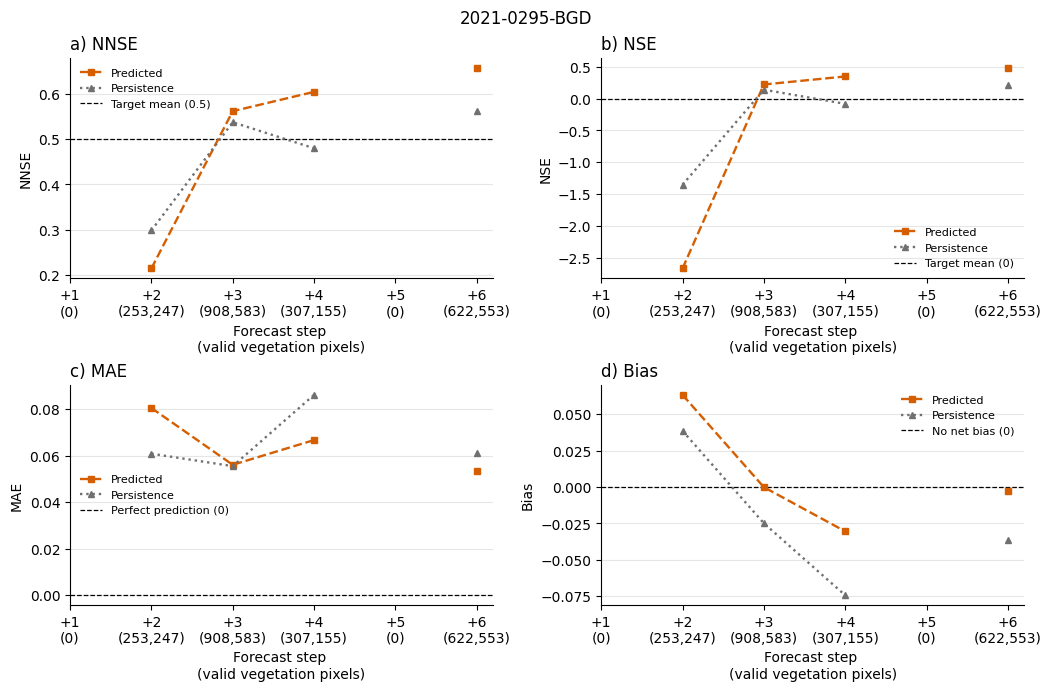

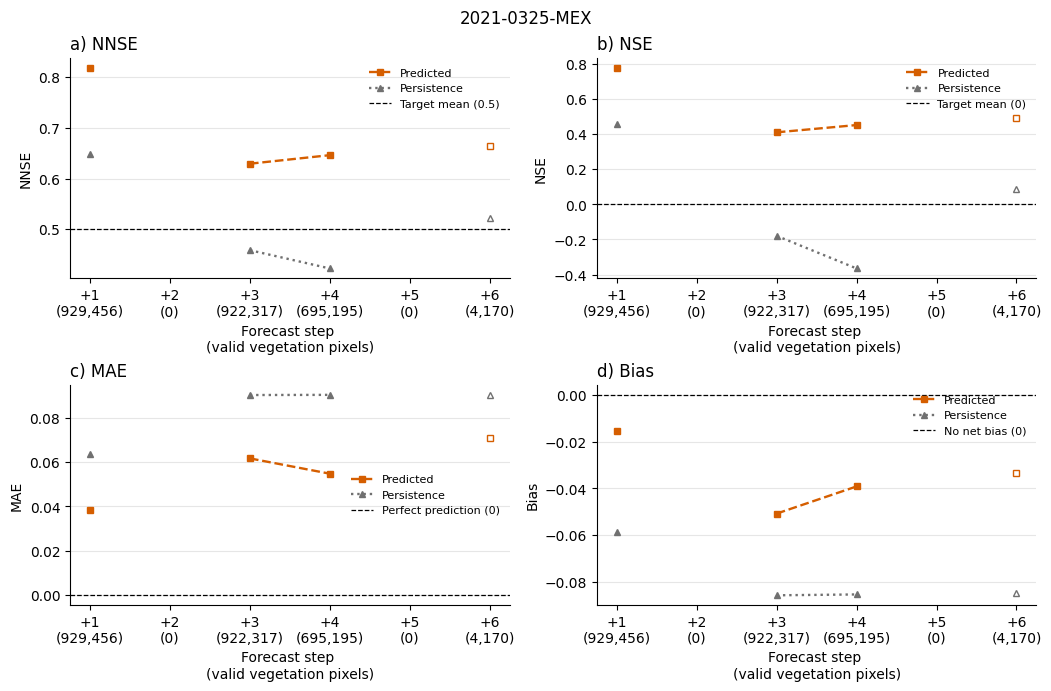

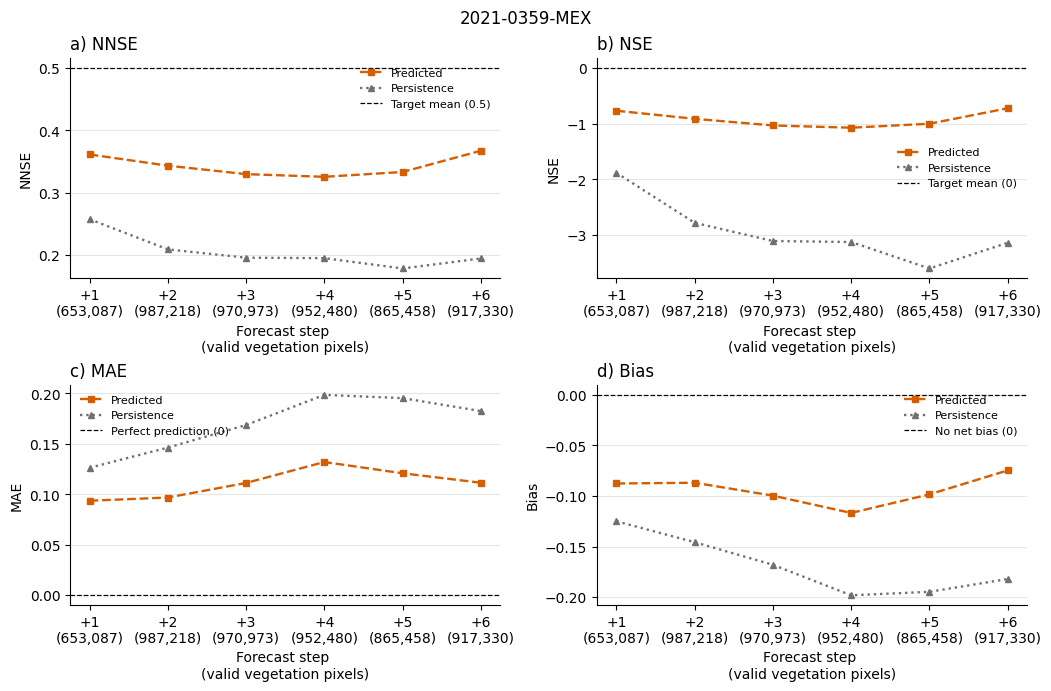

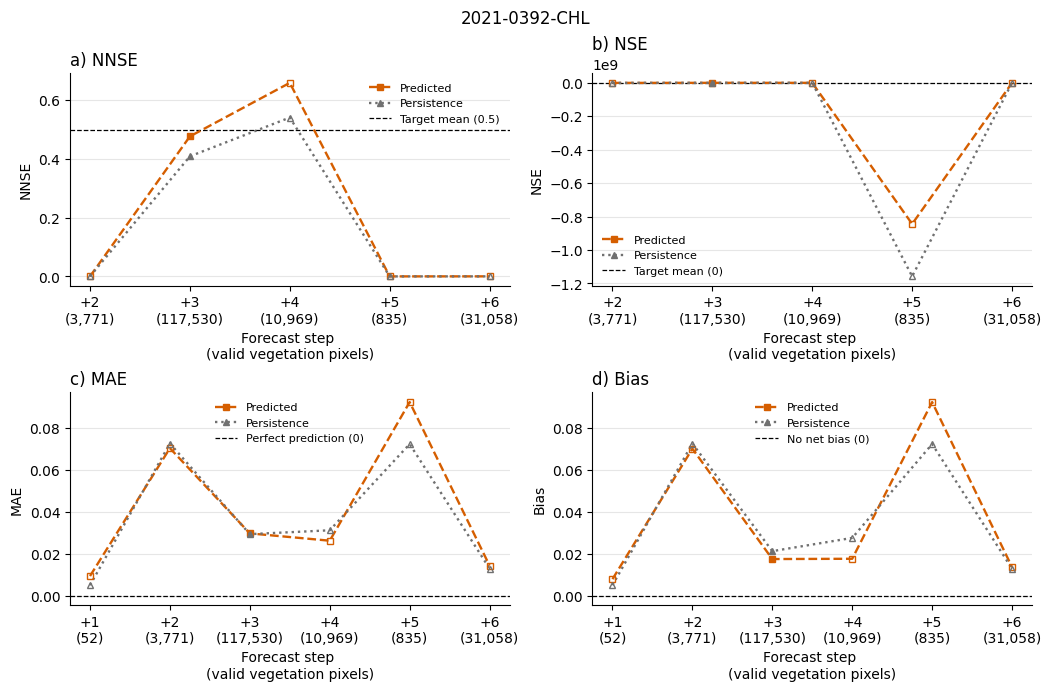

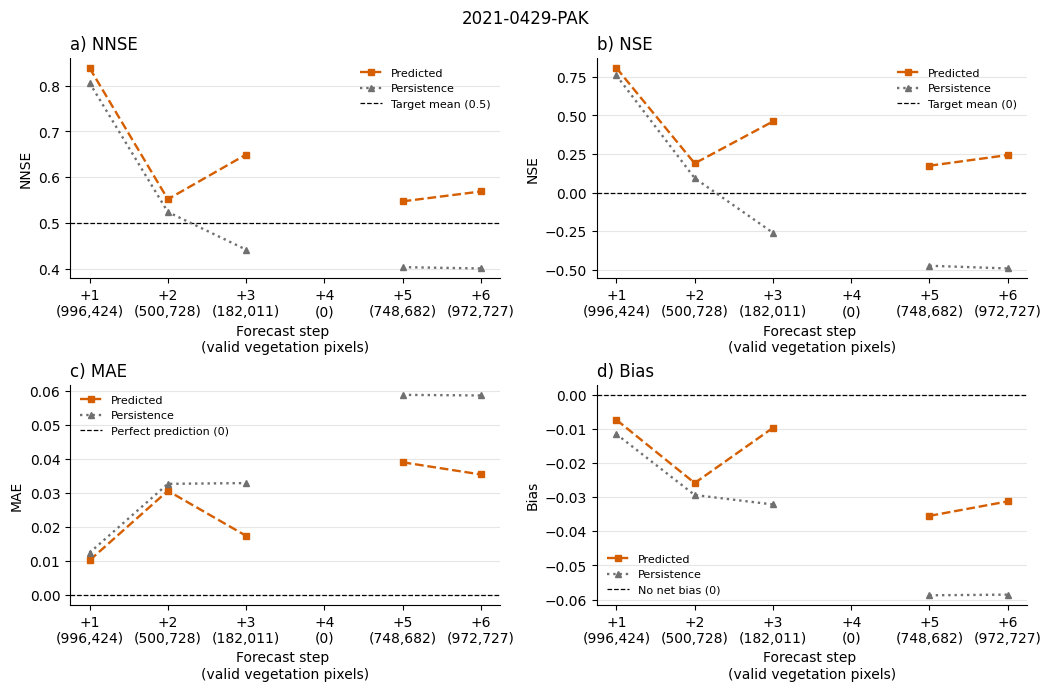

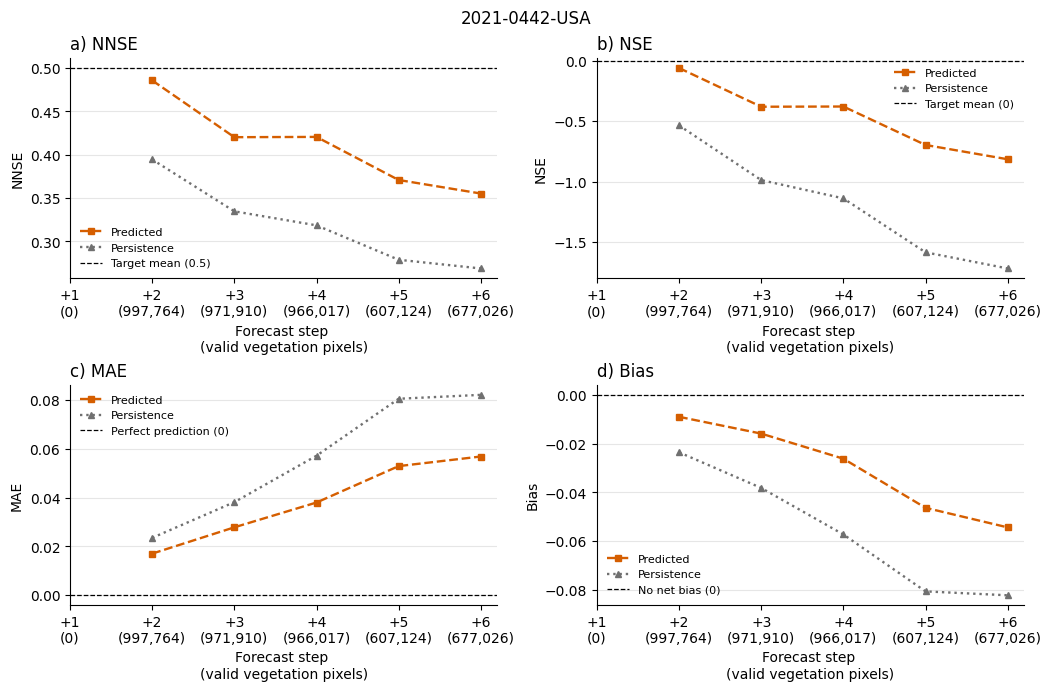

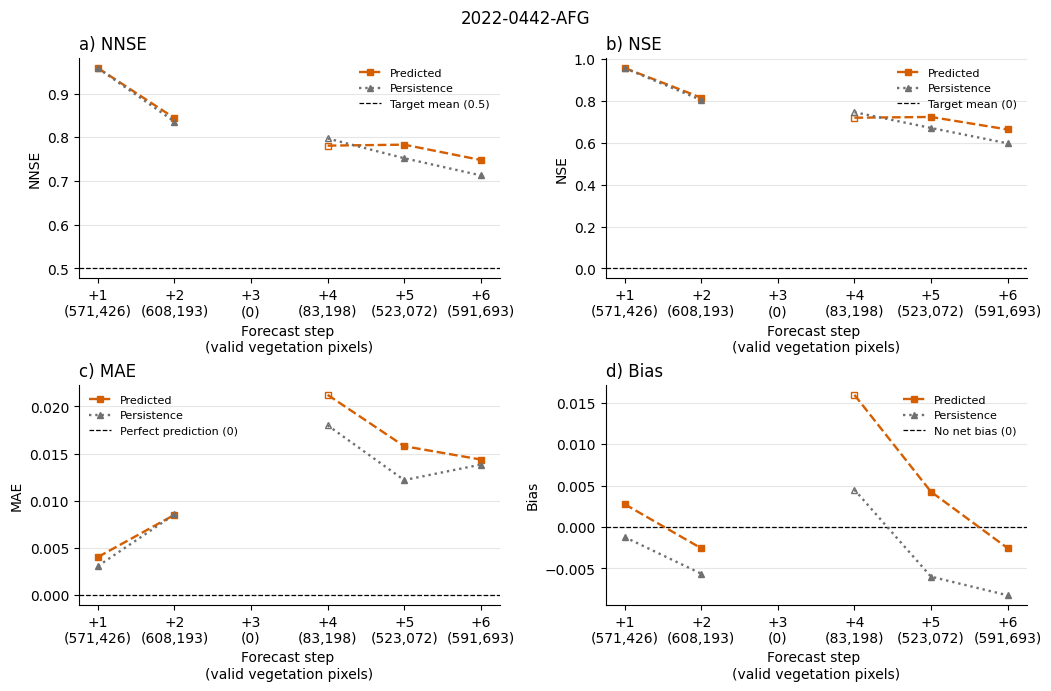

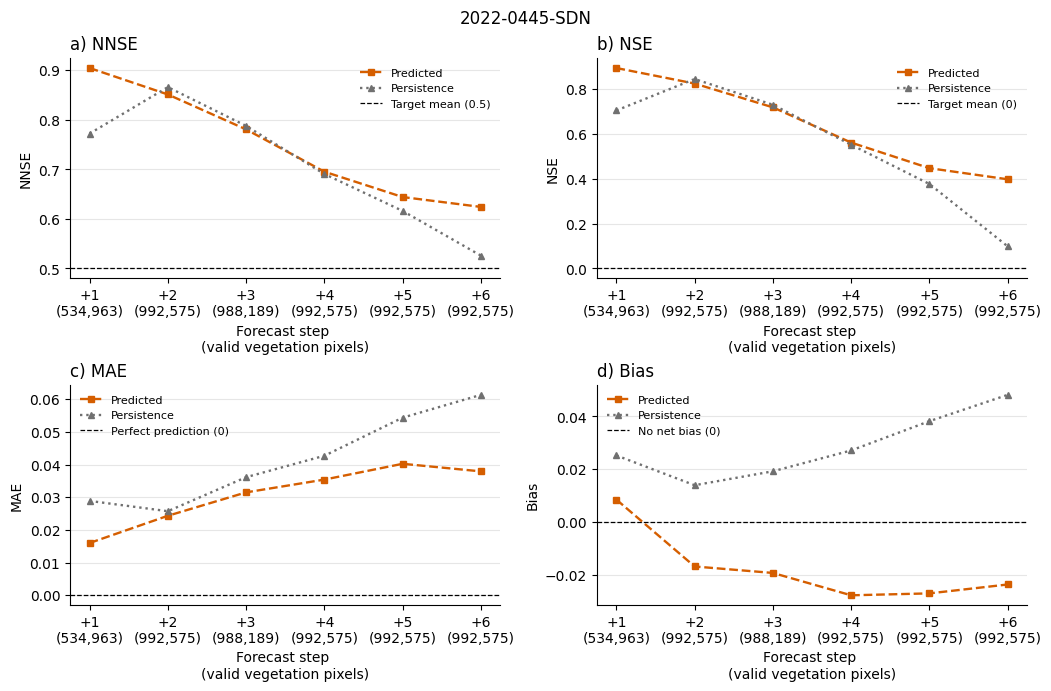

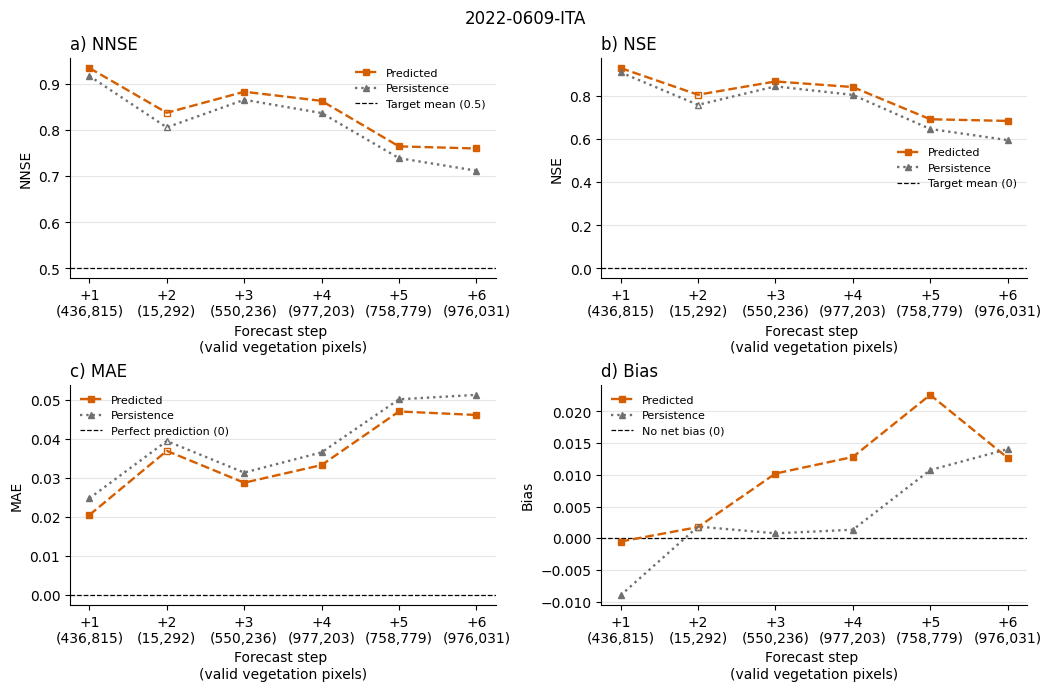

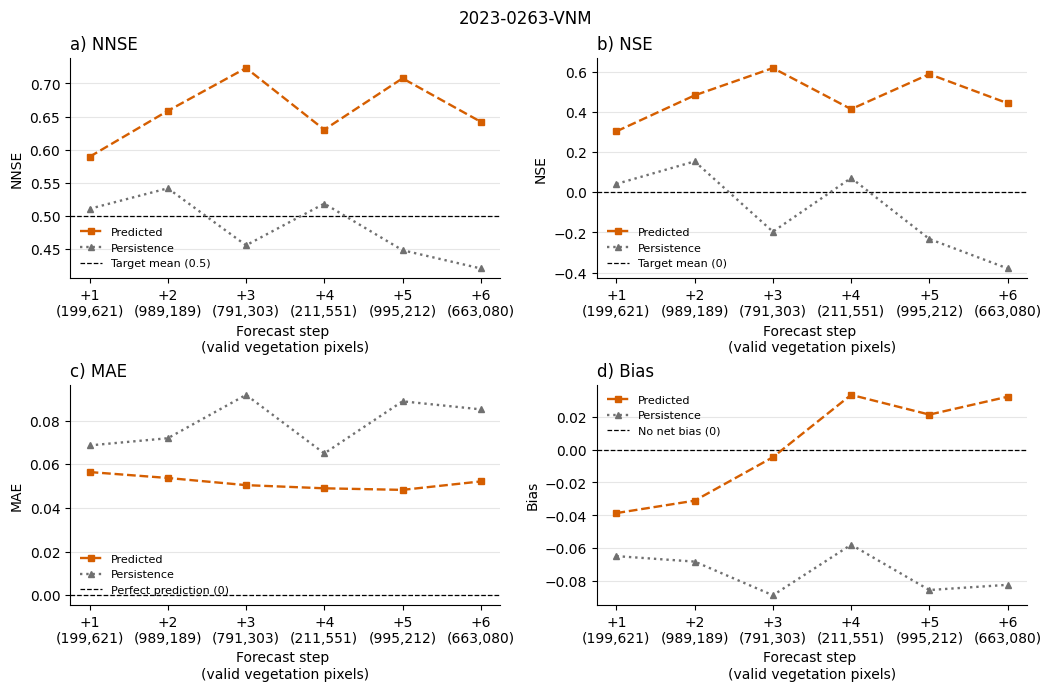

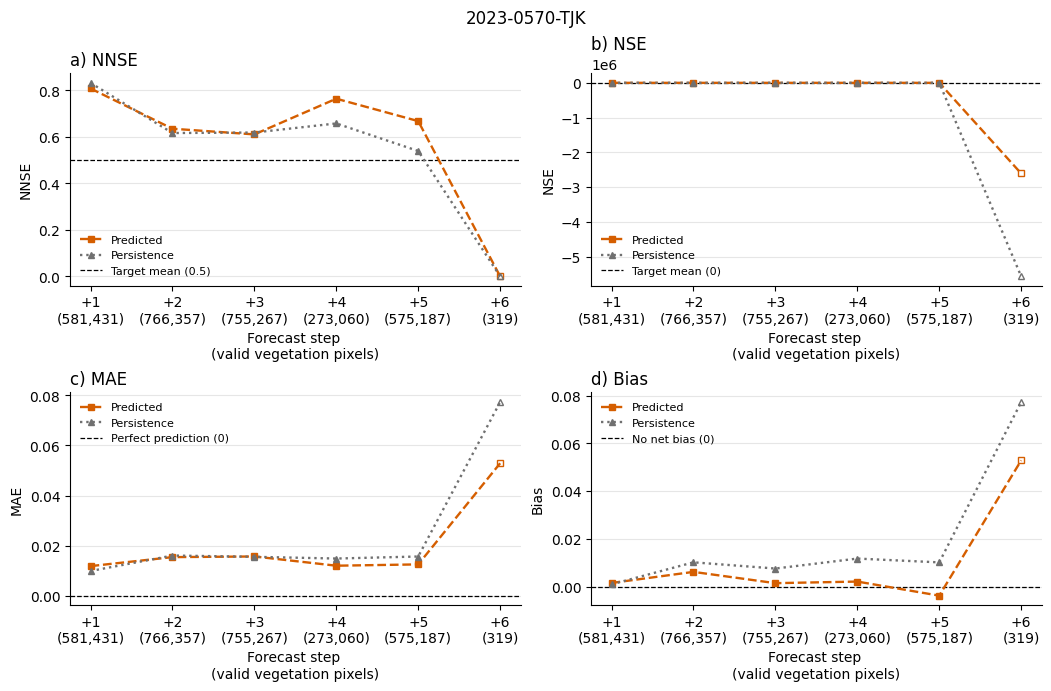

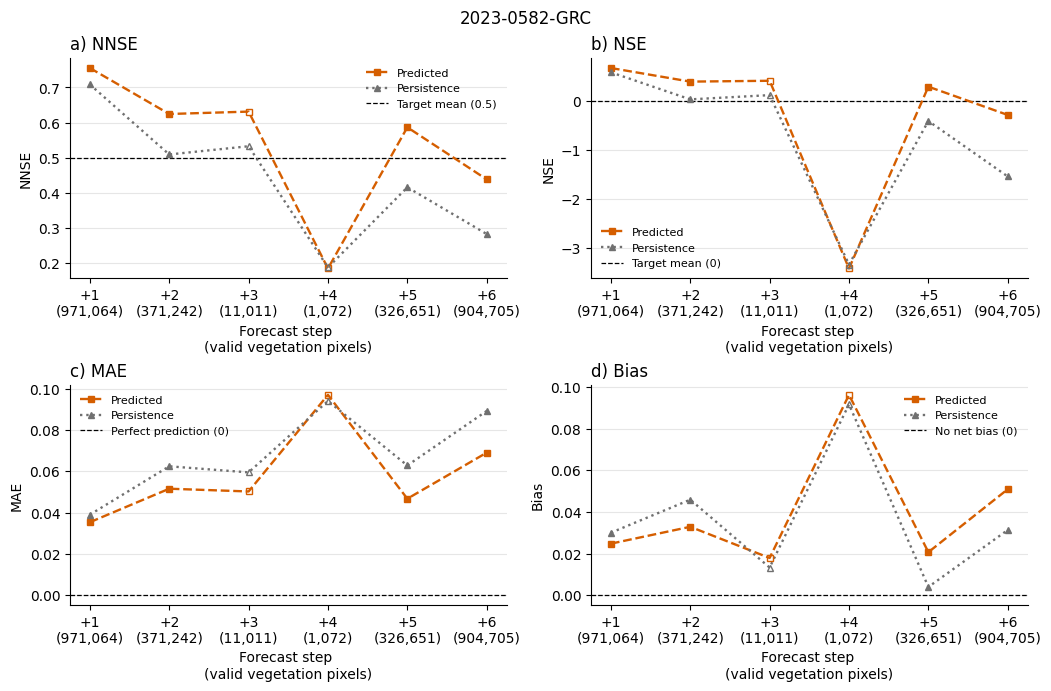

In [61]:
for CUBE in selected:
    policy = "off"
    filename = f"single_cube_trajectories/lead_time_metrics_{CUBE}_SD_{SHOW_SD}.png"
    new_dir = OUTPUT / "single_cube_trajectories"
    new_dir.mkdir(parents=True, exist_ok=True)
    policy = "off"
    single_scores = summarize(stats, mode="single", eligibility=policy, metrics=PLOT_METRICS, ids=[CUBE])
    plot_metrics(single_scores, mode="single", eligibility=policy, title=CUBE, filename=filename, **plot_options);

### 5d. Values behind a figure


In [17]:
fig_data = summarize(stats, mode="cube", eligibility="slice", metrics=PLOT_METRICS, ids=selected)
fig_data.pivot(index=["metric", "step", "n_cubes", "n_pixels"], columns="curve", values="value").round(5)

curve                         Persistence  Predicted
metric step n_cubes n_pixels                        
Bias   1    16      8776959      -0.02372   -0.00654
       2    12      9098258      -0.01367   -0.00472
       3    18      12846127     -0.03693   -0.01309
       4    14      9411826      -0.04924   -0.02013
       5    14      10731803     -0.03451   -0.01120
       6    14      11229499     -0.04404   -0.01231
MAE    1    16      8776959       0.03972    0.03036
       2    12      9098258       0.04105    0.03483
       3    18      12846127      0.05317    0.03860
       4    14      9411826       0.06346    0.05093
       5    14      10731803      0.05915    0.03917
       6    14      11229499      0.07123    0.05403
NNSE   1    16      8776959       0.69500    0.75181
       2    12      9098258       0.57297    0.61070
       3    18      12846127      0.54924    0.61669
       4    14      9411826       0.54194    0.54931
       5    14      10731803      0.48921    0.57423
       6    14      11229499      0.42930    0.48189
NSE    1    16      8776959       0.30862    0.58153
       2    12      9098258      -0.06541    0.10067
       3    18      12846127     -0.11001    0.24397
       4    14      9411826      -0.17011   -0.21938
       5    14      10731803     -0.56745   -0.03247
       6    14      11229499     -1.55267   -1.57985